# 01. Exploratory Data Analysis (EDA) — Used Car Price Prediction

**Project:** Classical Supervised Learning (Regression) — CarDekho Used Car Price Prediction  
**Input Dataset:** `../dataset/raw/car.csv` (4,000 records × 8 columns sampled reproducibly from `CAR DETAILS FROM CAR DEKHO.csv`)  
**Target Variable ($y$):** `selling_price` (in **INR** — Indian Rupees)  

### Objectives (Aligned with Course PDFs)
1. Audit dataset structure, data types (`Nominal`, `Ordinal`, `Interval`, `Ratio`), and summary statistics.
2. Check missing values, blank strings, exact duplicates, and domain anomalies.
3. Perform Univariate, Bivariate (`km_driven` vs. `selling_price`, `year` vs. `selling_price`), and Multivariate (Pearson correlation heatmap) visualizations following good design principles (clear titles, INR units, readable Top-N brand charts).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Load & Inspect the 4,000-Record Dataset

In [2]:
df = pd.read_csv("../dataset/raw/car.csv")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(10)

Dataset shape: (4000, 8)
Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


                                   name  year  ... transmission         owner
0                      Renault KWID RXL  2016  ...       Manual   Third Owner
1     Mahindra Scorpio VLS AT 2.2 mHAWK  2010  ...    Automatic  Second Owner
2            Datsun RediGO 1.0 T Option  2018  ...       Manual   First Owner
3  Tata Indica Vista Aqua 1.3 Quadrajet  2010  ...       Manual  Second Owner
4             Hyundai i20 Active 1.4 SX  2018  ...       Manual   First Owner
5                Mahindra XUV500 W6 2WD  2014  ...       Manual  Second Owner
6                Maruti Swift Dzire ZDI  2014  ...       Manual   First Owner
7           Maruti Ertiga SHVS ZDI Plus  2017  ...       Manual   First Owner
8       Hyundai Grand i10 1.2 CRDi Asta  2019  ...       Manual   First Owner
9                Mahindra XUV500 W8 2WD  2013  ...       Manual   First Owner

[10 rows x 8 columns]

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4000 non-null   str  
 1   year           4000 non-null   int64
 2   selling_price  4000 non-null   int64
 3   km_driven      4000 non-null   int64
 4   fuel           4000 non-null   str  
 5   seller_type    4000 non-null   str  
 6   transmission   4000 non-null   str  
 7   owner          4000 non-null   str  
dtypes: int64(3), str(5)
memory usage: 250.1 KB


In [4]:
print("=== Numerical Summary Statistics ===")
print(df.describe().round(2))
print("\n=== Categorical Summary Statistics ===")
print(df.describe(include="object"))

=== Numerical Summary Statistics ===
          year  selling_price  km_driven
count  4000.00        4000.00    4000.00
mean   2013.11      504731.64   66220.14
std       4.23      580624.57   46786.60
min    1992.00       30000.00       1.00
25%    2011.00      208749.75   35000.00
50%    2014.00      350000.00   60000.00
75%    2016.00      600000.00   90000.00
max    2020.00     8900000.00  806599.00

=== Categorical Summary Statistics ===
                          name    fuel seller_type transmission        owner
count                     4000    4000        4000         4000         4000
unique                    1433       5           3            2            5
top     Maruti Swift Dzire VDI  Diesel  Individual       Manual  First Owner
freq                        60    1983        2994         3587         2616


## 2. Data Quality Audit: Missing Values, Duplicates & Suspicious Entries

In [5]:
# 1. Missing values & blank strings
print("Missing (NaN) counts per column:")
print(df.isnull().sum())

blank_counts = {
    col: int((df[col].astype(str).str.strip() == "").sum())
    for col in df.select_dtypes(include="object").columns
}
print("\nBlank/whitespace string counts:", blank_counts)

# 2. Exact duplicates
dup_count = int(df.duplicated().sum())
print(f"\nExact duplicate rows: {dup_count} ({dup_count / len(df) * 100:.2f}%)")
print(f"Unique rows remaining after deduplication: {len(df.drop_duplicates())}")

# 3. Domain anomaly check: near-zero km_driven
low_km = df[df["km_driven"] < 100]
print(f"\nRecords with km_driven < 100: {len(low_km)}")
if len(low_km) > 0:
    print(low_km)

Missing (NaN) counts per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Blank/whitespace string counts: {'name': 0, 'fuel': 0, 'seller_type': 0, 'transmission': 0, 'owner': 0}

Exact duplicate rows: 663 (16.57%)
Unique rows remaining after deduplication: 3337

Records with km_driven < 100: 1
                    name  year  ... transmission         owner
1320  Mahindra Quanto C6  2014  ...       Manual  Second Owner

[1 rows x 8 columns]


## 3. Univariate Analysis — Numerical Distributions & IQR Outlier Detection

=== IQR Outlier Analysis ===
selling_price: Q1=208,750, Q3=600,000, IQR=391,250, Fences=[-378,125.6, 1,186,875.4], Outliers=253
km_driven: Q1=35,000, Q3=90,000, IQR=55,000, Fences=[-47,500.0, 172,500.0], Outliers=101
year: Q1=2,011, Q3=2,016, IQR=5, Fences=[2,003.5, 2,023.5], Outliers=99


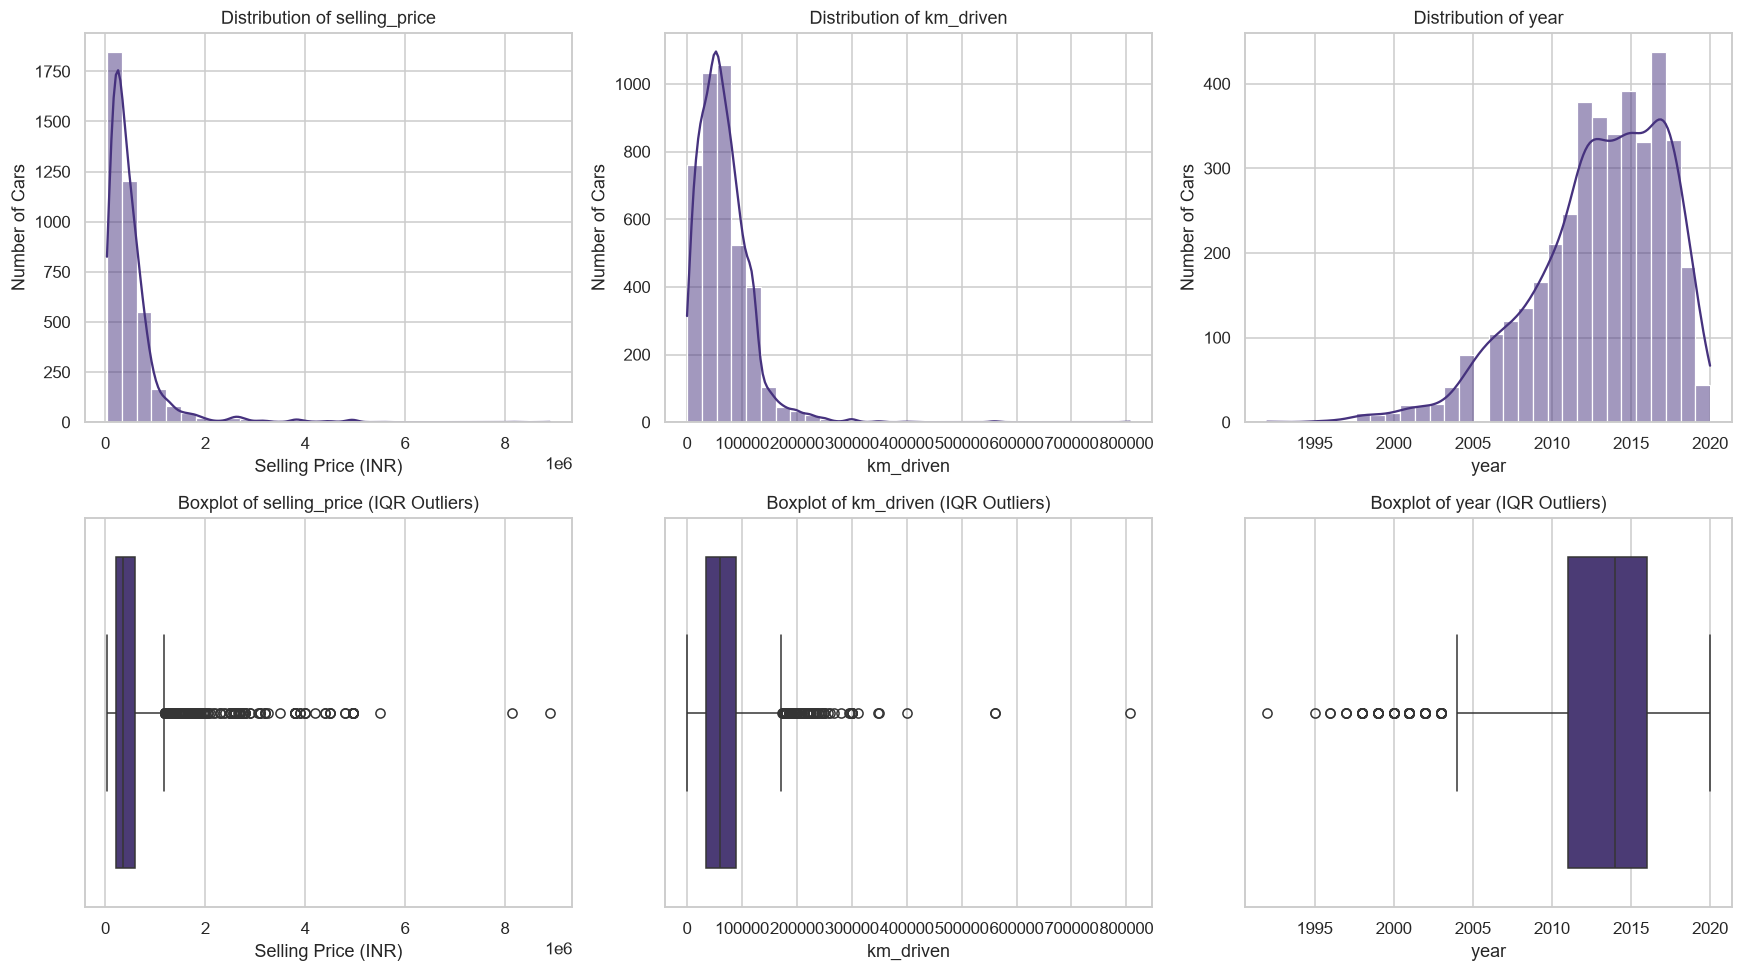

In [6]:
num_cols = ["selling_price", "km_driven", "year"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for idx, col in enumerate(num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[0, idx])
    xlabel = "Selling Price (INR)" if col == "selling_price" else col
    axes[0, idx].set_title(f"Distribution of {col}")
    axes[0, idx].set_xlabel(xlabel)
    axes[0, idx].set_ylabel("Number of Cars")

    sns.boxplot(x=df[col], ax=axes[1, idx])
    axes[1, idx].set_title(f"Boxplot of {col} (IQR Outliers)")
    axes[1, idx].set_xlabel(xlabel)

plt.tight_layout()
plt.show()

# Programmatic IQR outlier summary
print("=== IQR Outlier Analysis ===")
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = int(((df[col] < lower) | (df[col] > upper)).sum())
    print(f"{col}: Q1={q1:,.0f}, Q3={q3:,.0f}, IQR={iqr:,.0f}, Fences=[{lower:,.1f}, {upper:,.1f}], Outliers={n_out}")

## 4. Univariate Analysis — Top Brands & Categorical Features

Instead of plotting all 1,400+ raw `name` strings (unreadable chartjunk), we extract `brand` from the first token of `name` and visualize the Top 12 brands alongside `fuel`, `seller_type`, `transmission`, and `owner`.

Unique car names: 1433 | Unique brands: 29


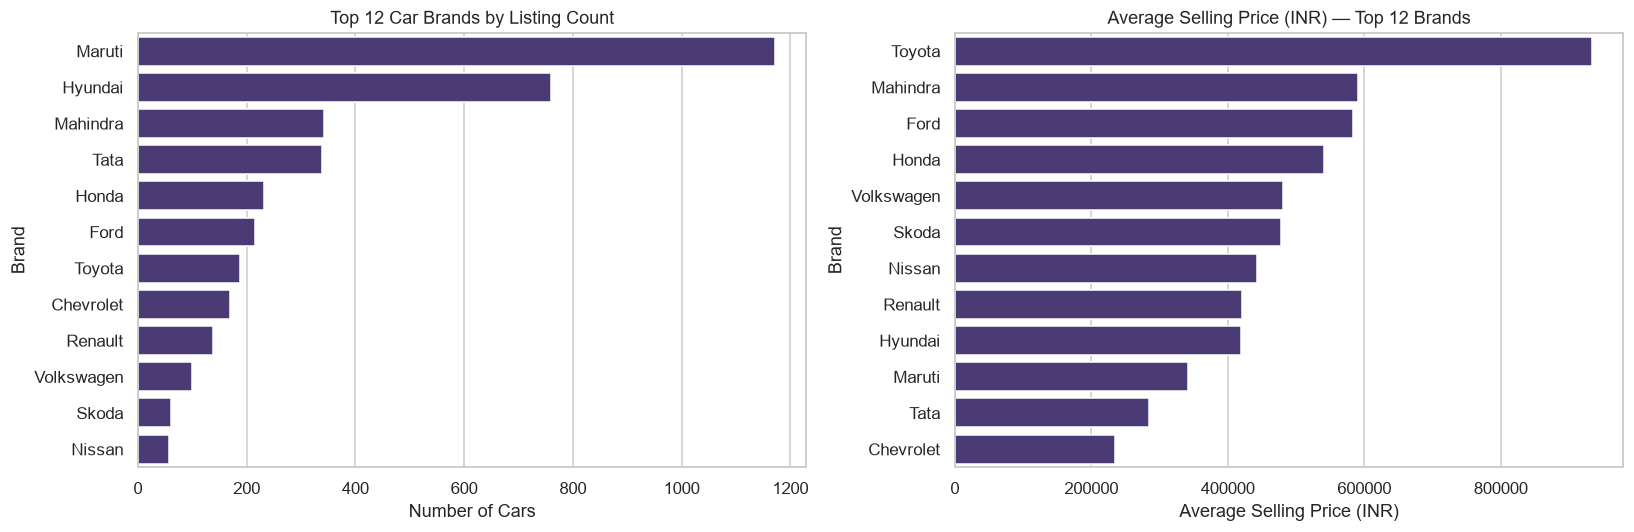

In [7]:
df["brand"] = df["name"].astype(str).str.strip().str.split().str[0]
print(f"Unique car names: {df['name'].nunique()} | Unique brands: {df['brand'].nunique()}")

top_brands = df["brand"].value_counts().head(12)
brand_avg_price = (
    df[df["brand"].isin(top_brands.index)]
    .groupby("brand")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=top_brands.values, y=top_brands.index, ax=axes[0])
axes[0].set_title("Top 12 Car Brands by Listing Count")
axes[0].set_xlabel("Number of Cars")
axes[0].set_ylabel("Brand")

sns.barplot(x=brand_avg_price.values, y=brand_avg_price.index, ax=axes[1])
axes[1].set_title("Average Selling Price (INR) — Top 12 Brands")
axes[1].set_xlabel("Average Selling Price (INR)")
axes[1].set_ylabel("Brand")
plt.tight_layout()
plt.show()


--- fuel ---
fuel
Diesel      1983
Petrol      1957
CNG           36
LPG           23
Electric       1
Name: count, dtype: int64

--- seller_type ---
seller_type
Individual          2994
Dealer               912
Trustmark Dealer      94
Name: count, dtype: int64

--- transmission ---
transmission
Manual       3587
Automatic     413
Name: count, dtype: int64

--- owner ---
owner
First Owner             2616
Second Owner            1019
Third Owner              275
Fourth & Above Owner      74
Test Drive Car            16
Name: count, dtype: int64


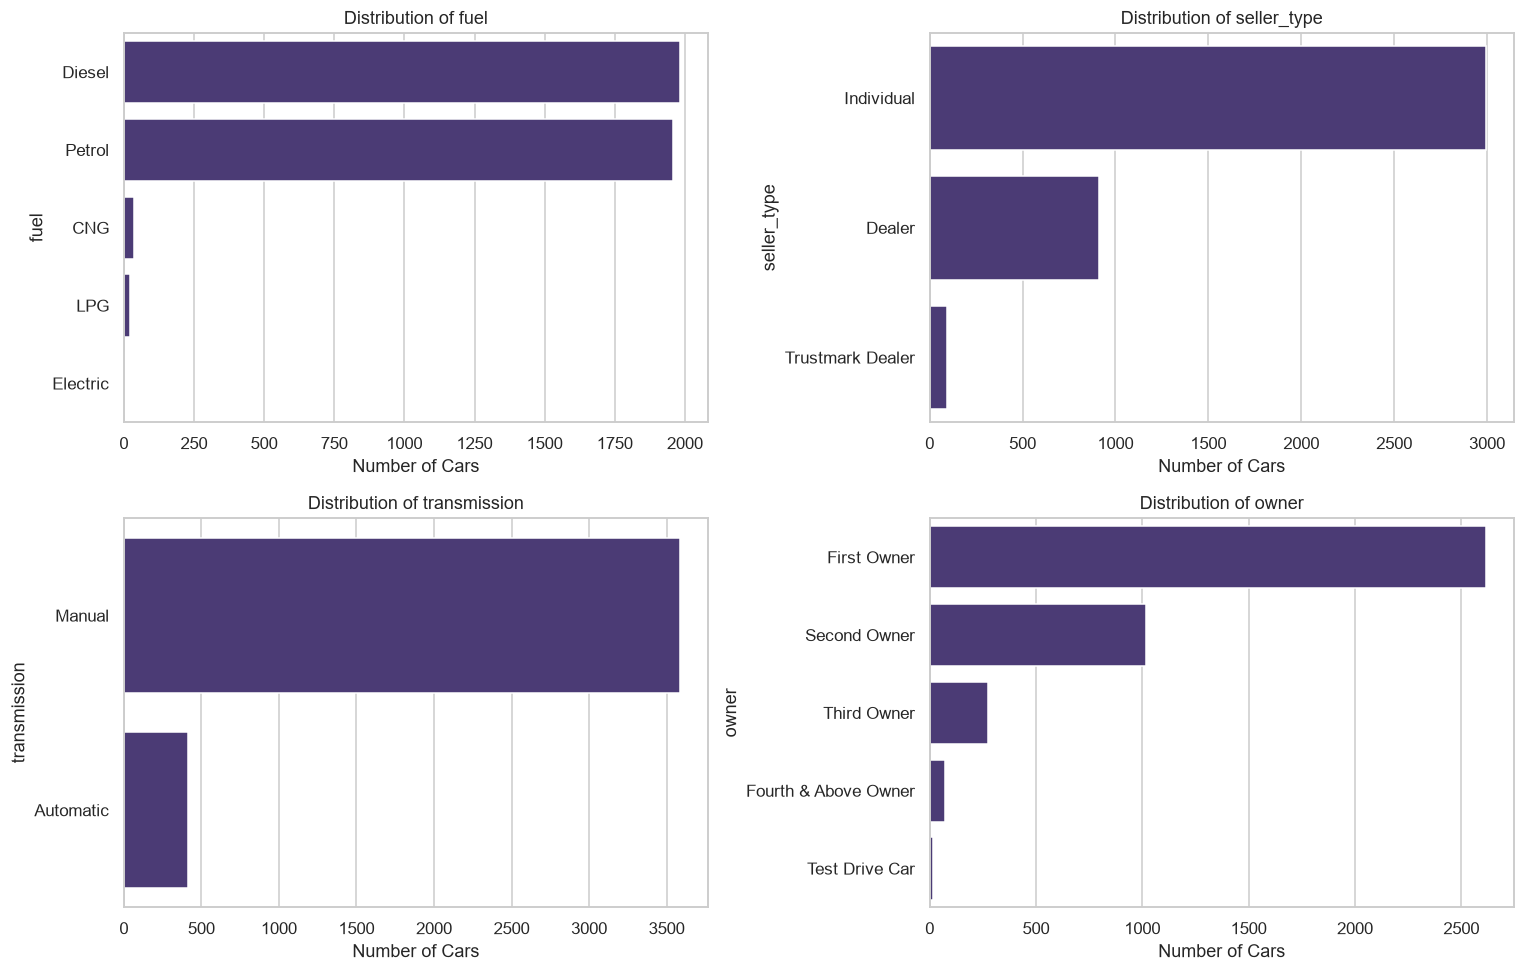

In [8]:
cat_cols = ["fuel", "seller_type", "transmission", "owner"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Number of Cars")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())

## 5. Bivariate Analysis — Predictors vs. `selling_price` (INR)

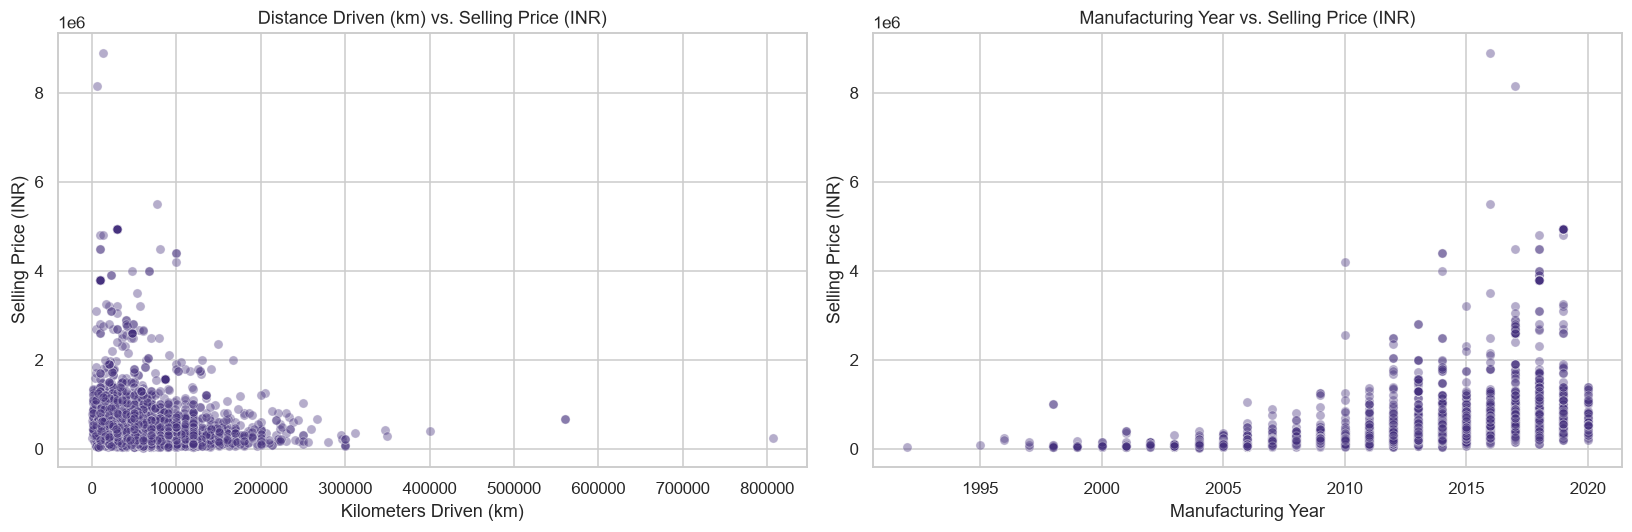

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.4, ax=axes[0])
axes[0].set_title("Distance Driven (km) vs. Selling Price (INR)")
axes[0].set_xlabel("Kilometers Driven (km)")
axes[0].set_ylabel("Selling Price (INR)")

sns.scatterplot(data=df, x="year", y="selling_price", alpha=0.4, ax=axes[1])
axes[1].set_title("Manufacturing Year vs. Selling Price (INR)")
axes[1].set_xlabel("Manufacturing Year")
axes[1].set_ylabel("Selling Price (INR)")

plt.tight_layout()
plt.show()

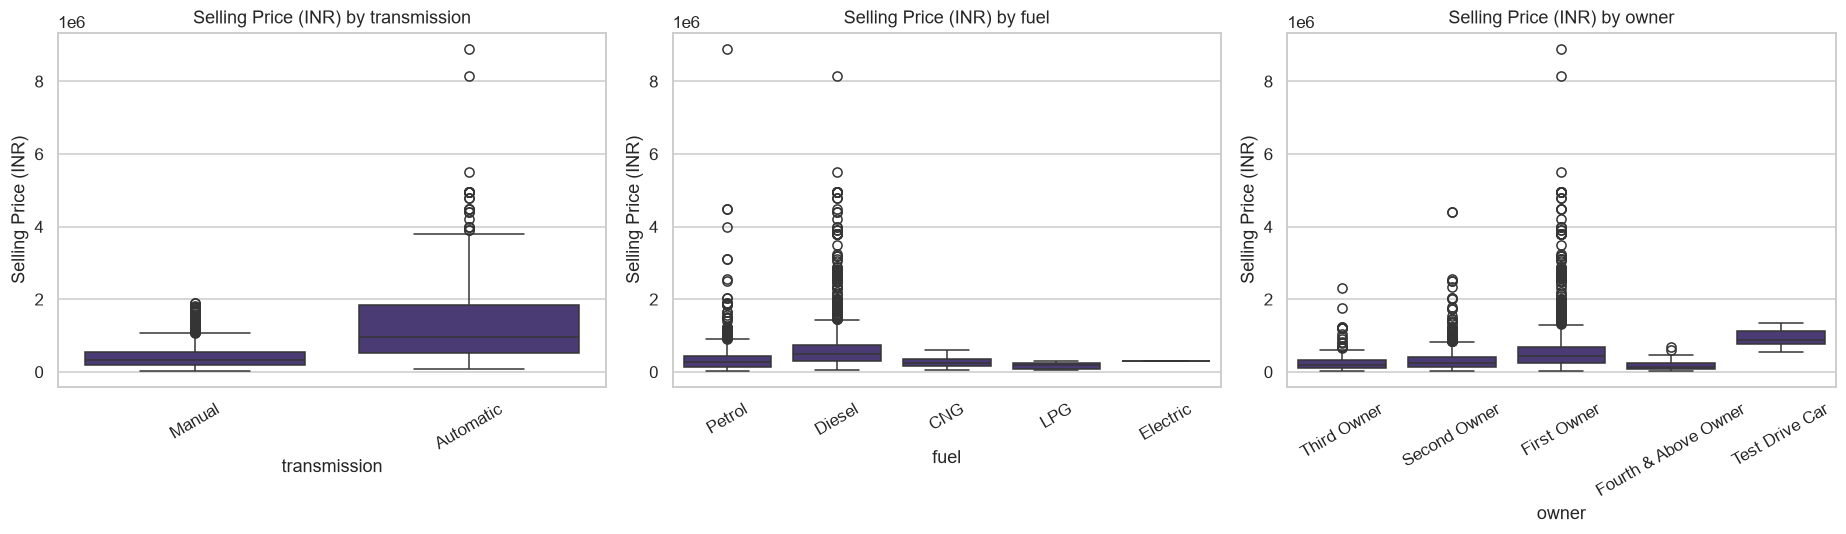

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["transmission", "fuel", "owner"]):
    sns.boxplot(data=df, x=col, y="selling_price", ax=ax)
    ax.set_title(f"Selling Price (INR) by {col}")
    ax.set_ylabel("Selling Price (INR)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 6. Multivariate Analysis — Pearson Correlation Heatmap

Pearson Correlation Matrix:
               selling_price    year  km_driven
selling_price         1.0000  0.4131    -0.1909
year                  0.4131  1.0000    -0.4142
km_driven            -0.1909 -0.4142     1.0000


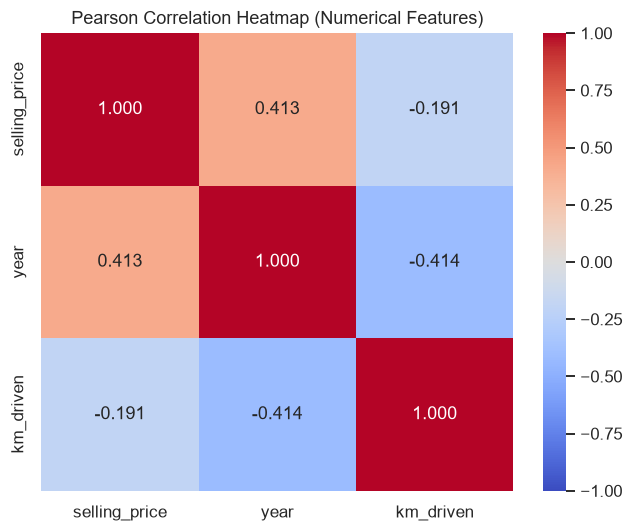

In [11]:
corr_matrix = df[["selling_price", "year", "km_driven"]].corr(method="pearson")
print("Pearson Correlation Matrix:")
print(corr_matrix.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson Correlation Heatmap (Numerical Features)")
plt.tight_layout()
plt.show()

## 7. Key EDA Findings & Next Steps for Notebook 02

1. **Dataset Size & Integrity:** `../dataset/raw/car.csv` contains **4,000 rows × 8 columns** with **0 missing values**, **0 blank strings**, and **663 exact duplicate rows** (3,337 unique listings). Duplicates must be removed in Notebook 02 prior to splitting to prevent train/test data leakage.
2. **Skewness & Outliers:** `selling_price` (INR) and `km_driven` are right-skewed with upper-tail luxury vehicles and high-mileage listings; near-zero `km_driven < 100` non-test-drive rows should be inspected and cleaned.
3. **Feature Signals:** Newer manufacturing `year`, `Automatic` transmission, `Diesel` fuel, `First Owner` status, and luxury `brand`s exhibit higher prices, while `km_driven` shows a negative relationship with `selling_price`.
4. **High Cardinality & Rare Classes:** Raw `name` has 1,400+ values (engineer `brand` and group rare brands); rare classes such as `Electric` (1 row) require `OneHotEncoder(handle_unknown="ignore")`.